Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

Load Dataset

In [2]:
df = pd.read_csv(
    r"C:\Users\dolly\Downloads\bank+marketing\bank\bank-full.csv",
    sep=";"
)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Dataset Shape

In [3]:
print(df.shape)

(45211, 17)


Dataset Information

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


Missing Values

In [5]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Statistics

In [6]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Class Distribution

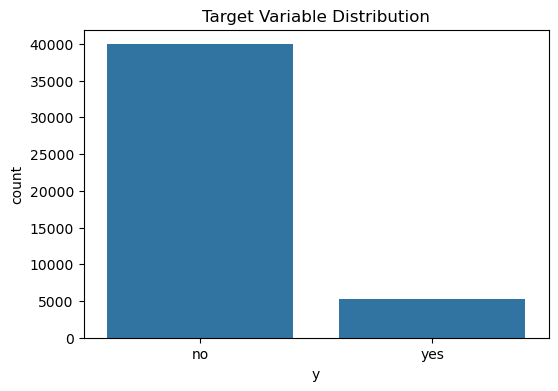

In [7]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="y")
plt.title("Target Variable Distribution")
plt.show()

Age Distribution

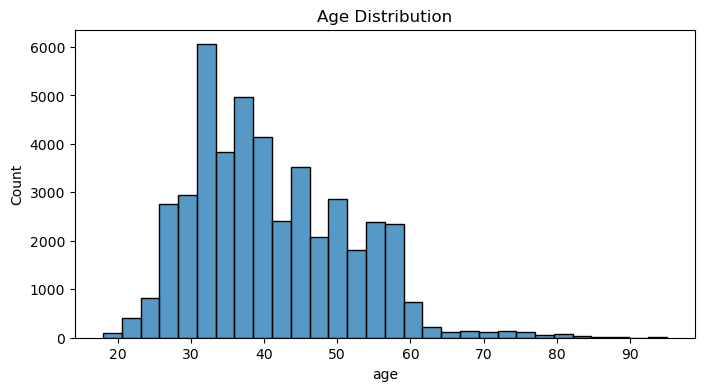

In [8]:
plt.figure(figsize=(8,4))
sns.histplot(df["age"], bins=30)
plt.title("Age Distribution")
plt.show()

Job Distribution

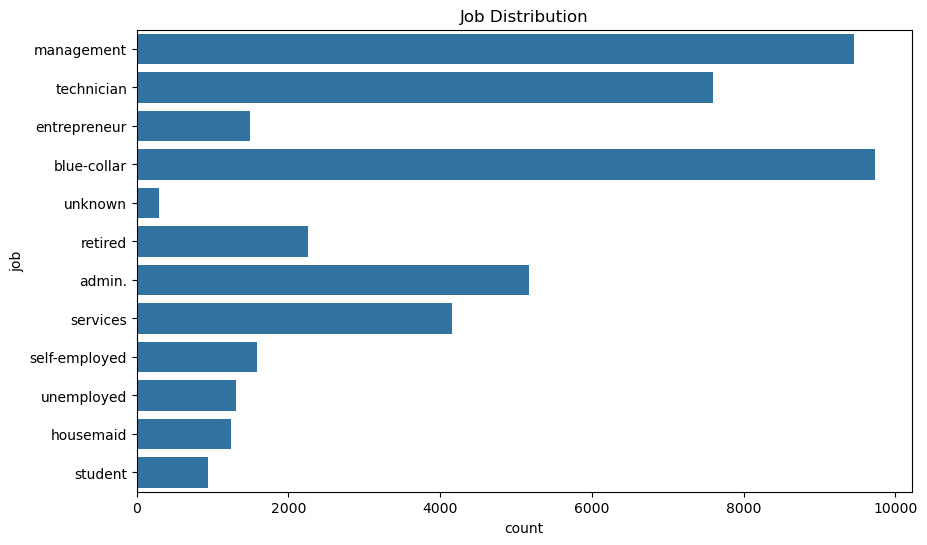

In [9]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, y="job")
plt.title("Job Distribution")
plt.show()

Correlation Heatmap

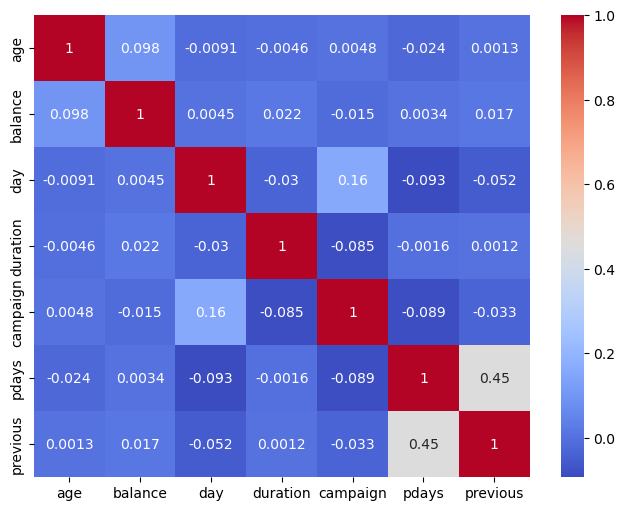

In [10]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

Separate Features and Target

In [12]:
X = df.drop("y", axis=1)
y = df["y"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (45211, 16)
Target Shape: (45211,)


Encode the Target Variable

In [13]:
target_encoder = LabelEncoder()

y = target_encoder.fit_transform(y)

print(pd.Series(y).value_counts())

0    39922
1     5289
Name: count, dtype: int64


Encode Categorical Features

In [14]:
label_encoders = {}

for col in X.select_dtypes(include="object").columns:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col])
    label_encoders[col] = encoder

print("Encoding Completed Successfully")

Encoding Completed Successfully


Verify Data Types

In [15]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  int64
 2   marital    45211 non-null  int64
 3   education  45211 non-null  int64
 4   default    45211 non-null  int64
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  int64
 7   loan       45211 non-null  int64
 8   contact    45211 non-null  int64
 9   day        45211 non-null  int64
 10  month      45211 non-null  int64
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  int64
dtypes: int64(16)
memory usage: 5.5 MB


Train-Test Split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (36168, 16)
Testing Data: (9043, 16)


Feature Scaling

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling Completed Successfully")

Scaling Completed Successfully


Create Models Folder

In [18]:
os.makedirs("models", exist_ok=True)

print("Models folder created")

Models folder created


In [19]:
joblib.dump(scaler, "models/scaler.pkl")

print("Scaler Saved Successfully")

Scaler Saved Successfully


Create Models

In [20]:
models = {

    "Logistic Regression": LogisticRegression(
        random_state=42,
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="linear",
        random_state=42
    )
}

print("All Models Created Successfully")

All Models Created Successfully


Train All Models

In [21]:
for name, model in models.items():

    print(f"Training {name}...")

    if name in ["Decision Tree", "Naive Bayes"]:
        model.fit(X_train, y_train)
    else:
        model.fit(X_train_scaled, y_train)

    print(f"{name} Completed")

print("\nAll Models Trained Successfully")

Training Logistic Regression...
Logistic Regression Completed
Training Decision Tree...
Decision Tree Completed
Training KNN...
KNN Completed
Training Naive Bayes...
Naive Bayes Completed
Training Support Vector Machine...
Support Vector Machine Completed

All Models Trained Successfully


Evaluate All Models

In [22]:
results = []

for name, model in models.items():

    if name in ["Decision Tree", "Naive Bayes"]:
        X_test_used = X_test
    else:
        X_test_used = X_test_scaled

    y_pred = model.predict(X_test_used)

    if name == "Support Vector Machine":
        y_score = model.decision_function(X_test_used)
    else:
        y_score = model.predict_proba(X_test_used)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    mcc = matthews_corrcoef(y_test, y_pred)

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        auc,
        mcc
    ])

Create Comparison Table

In [23]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUC",
        "MCC"
    ]
)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,AUC,MCC
2,KNN,0.892292,0.571672,0.316635,0.407543,0.808924,0.372370
0,Logistic Regression,0.891408,0.594527,0.225898,0.327397,0.872583,0.320453
4,Support Vector Machine,0.883003,0.000000,0.000000,0.000000,0.855014,0.000000
1,Decision Tree,0.876921,0.474275,0.479206,0.476728,0.704412,0.406996
3,Naive Bayes,0.844521,0.365948,0.448960,0.403226,0.815968,0.317083


In [24]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print(results_df)

                    Model  Accuracy  Precision    Recall  F1 Score       AUC  \
2                     KNN  0.892292   0.571672  0.316635  0.407543  0.808924   
0     Logistic Regression  0.891408   0.594527  0.225898  0.327397  0.872583   
4  Support Vector Machine  0.883003   0.000000  0.000000  0.000000  0.855014   
1           Decision Tree  0.876921   0.474275  0.479206  0.476728  0.704412   
3             Naive Bayes  0.844521   0.365948  0.448960  0.403226  0.815968   

        MCC  
2  0.372370  
0  0.320453  
4  0.000000  
1  0.406996  
3  0.317083  


In [25]:
os.makedirs("models", exist_ok=True)

for name, model in models.items():

    filename = name.lower().replace(" ", "_") + ".pkl"

    joblib.dump(model, "models/" + filename)

print("All Models Saved Successfully")

All Models Saved Successfully


In [26]:
# Create test dataset using ORIGINAL column names
test_df = X_test.copy()

# Add target column
test_df["Target"] = y_test

# Save CSV
test_df.to_csv("test_data.csv", index=False)

print("test_data.csv created successfully!")

test_data.csv created successfully!
